In [1]:
from pathlib import Path
from functools import partial
from types import SimpleNamespace
import itertools
import inspect
import time

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import marimo as mo
import networkx as nx
from sklearn.decomposition import PCA
from sklearn.metrics.cluster import adjusted_rand_score, fowlkes_mallows_score
from ClusterValid import ClusterIndexCalculator
from sklearn.decomposition import FactorAnalysis
from numba import njit
from factor_analyzer import FactorAnalyzer
from factor_analyzer.rotator import Rotator
from statsmodels.multivariate.factor_rotation import rotate_factors
from scipy import stats
from sklearn.metrics import silhouette_score

import magics
from utils import AgglomerativeTree
from utils import fa_predict
from utils import favm_predict
from utils import fix_labels
from utils import gen_test_collection
from utils import pca_predict
from utils import plot_clustered_corrmat
from utils import InternalIndex
from utils import OptimumRule
from utils import get_index

In [2]:
def to_laconic(secs: float) -> str:
    td = pd.Timedelta(secs, unit="s")
    return str(td).removeprefix("0 days ")

def make_stopwatch():
    start_time = time.time()
    def stopwatch():
        return to_laconic(int(time.time() - start_time))
    return stopwatch

In [3]:
import pickle
import json
from compression import gzip
from compression import bz2
from compression import lzma
from compression import zstd

_OPENERS = {
    "gzip": gzip.open,
    "bz2": bz2.open,
    "lzma": lzma.open,
    "xz": lzma.open,
    "zstd": zstd.open,
    None: open,
}

_EXT_TO_COMPRESSION = {
    ".gz": "gzip",
    ".bz2": "bz2",
    ".xz": "lzma",
    ".lzma": "lzma",
    ".zst": "zstd"
}

def _resolve_opener(suffix, compression):
    if compression == "auto":
        compression = _EXT_TO_COMPRESSION.get(suffix)
    return _OPENERS[compression]

def save_to(obj, path, compression="auto"):
    path = Path(path)
    opener = _resolve_opener(path.suffix, compression)
    match path.suffixes[0]:
        case ".pickle" | ".pkl":
            with opener(path, "wb") as file:
                return pickle.dump(obj, file)
        case ".json":
            with opener(path, "w") as file:
                return json.dump(obj, file, indent=2)
        case unknown_prefix:
            raise NotImplementedError(unknown_prefix)
                
def load_from(path, compression="auto"):
    path = Path(path)
    opener = _resolve_opener(path.suffix, compression)
    try:
        first_suffix = path.suffixes[0]
    except:
        print(path)
        raise
    match first_suffix:
        case ".pickle" | ".pkl":
            with opener(path, "rb") as file:
                return pickle.load(file)
        case ".json":
            with opener(path, "r") as file:
                return json.load(file)
        case unknown_prefix:
            raise NotImplementedError(unknown_prefix)

In [4]:
# _rng = np.random.default_rng(1000)
# collection1 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[2, 3, 4, 5, 6],
#     r_opts=[0.4, 0.5, 0.6, 0.7, 0.8],
#     n_versions=8,
#     seed=_rng
# )

In [5]:
# _rng = np.random.default_rng(2000)
# collection2 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[2, 3, 4, 5, 6],
#     r_opts=[0.4, 0.5, 0.6, 0.7, 0.8],
#     k1_opts=[1, 2, 3, 4],
#     n_versions=2,
#     seed=_rng
# )

In [6]:
# _rng = np.random.default_rng(3000)
# collection3 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[2, 3, 4, 5, 6],
#     r_opts=[
#         lambda k: [0.8]*(k//2) + [0.5]*(k//2 + k%2),
#         lambda k: [0.85] + [0.45]*(k - 1),
#         lambda k: [0.7]*(k - 1) + [0.35],
#         lambda k: list(np.linspace(0.7, 0.4, num=k).round(2)),
#         lambda k: sorted(_rng.uniform(0.35, 0.85, size=k).round(2)),
#     ],
#     n_versions=8,
#     seed=_rng
# )

In [7]:
# _rng = np.random.default_rng(4000)
# collection4 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[2, 3, 4, 5, 6],
#     r_opts=[
#         lambda k: [0.8]*(k//2) + [0.5]*(k//2 + k%2),
#         lambda k: [0.85] + [0.45]*(k - 1),
#         lambda k: [0.7]*(k - 1) + [0.35],
#         lambda k: list(np.linspace(0.7, 0.4, num=k).round(2)),
#         lambda k: sorted(_rng.uniform(0.35, 0.85, size=k).round(2)),
#     ],
#     k1_opts=[1, 2, 3, 4],
#     n_versions=2,
#     seed=_rng
# )

In [8]:
# _rng = np.random.default_rng(5000)
# collection5 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[
#         lambda k: [9]*(k//2) + [5]*(k//2 + k%2),
#         lambda k: [20] + [4]*(k - 1),
#         lambda k: [8]*(k - 1) + [3],
#         lambda k: list(np.arange(k, 0, -1) + 2),
#         lambda k: sorted(_rng.integers(2, 21, size=k), reverse=True),
#     ],
#     r_opts=[0.4, 0.5, 0.6, 0.7, 0.8],
#     n_versions=8,
#     seed=_rng
# )

In [9]:
# _rng = np.random.default_rng(6000)
# collection6 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[
#         lambda k: [9]*(k//2) + [5]*(k//2 + k%2),
#         lambda k: [20] + [4]*(k - 1),
#         lambda k: [8]*(k - 1) + [3],
#         lambda k: list(np.arange(k, 0, -1) + 2),
#         lambda k: sorted(_rng.integers(2, 21, size=k), reverse=True),
#     ],
#     r_opts=[0.4, 0.5, 0.6, 0.7, 0.8],
#     k1_opts=[1, 2, 3, 4],
#     n_versions=2,
#     seed=_rng
# )

In [10]:
# _rng = np.random.default_rng(7000)
# collection7 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[
#         lambda k: [9]*(k//2) + [5]*(k//2 + k%2),
#         lambda k: [20] + [4]*(k - 1),
#         lambda k: [8]*(k - 1) + [3],
#         lambda k: list(np.arange(k, 0, -1) + 2),
#         lambda k: sorted(_rng.integers(2, 21, size=k), reverse=True),
#     ],
#     r_opts=[
#         lambda k: [0.8]*(k//2) + [0.5]*(k//2 + k%2),
#         lambda k: [0.85] + [0.45]*(k - 1),
#         lambda k: [0.7]*(k - 1) + [0.35],
#         lambda k: list(np.linspace(0.7, 0.4, num=k).round(2)),
#         lambda k: sorted(_rng.uniform(0.35, 0.85, size=k).round(2)),
#     ],
#     n_versions=8,
#     seed=_rng
# )

In [11]:
# _rng = np.random.default_rng(8000)
# collection8 = gen_test_collection(
#     k_opts=[3, 4, 5, 6, 7],
#     f_opts=[
#         lambda k: [9]*(k//2) + [5]*(k//2 + k%2),
#         lambda k: [20] + [4]*(k - 1),
#         lambda k: [8]*(k - 1) + [3],
#         lambda k: list(np.arange(k, 0, -1) + 2),
#         lambda k: sorted(_rng.integers(2, 21, size=k), reverse=True),
#     ],
#     r_opts=[
#         lambda k: [0.8]*(k//2) + [0.5]*(k//2 + k%2),
#         lambda k: [0.85] + [0.45]*(k - 1),
#         lambda k: [0.7]*(k - 1) + [0.35],
#         lambda k: list(np.linspace(0.7, 0.4, num=k).round(2)),
#         lambda k: sorted(_rng.uniform(0.35, 0.85, size=k).round(2)),
#     ],
#     k1_opts=[1, 2, 3, 4],
#     n_versions=2,
#     seed=_rng
# )

In [12]:
# collections = [
#     collection1,
#     collection2,
#     collection3,
#     collection4,
#     collection5,
#     collection6,
#     collection7,
#     collection8,
# ]

In [14]:
collections = load_from("collections.pickle")

In [15]:
[collection1, collection2, 
 collection3, collection4, 
 collection5, collection6, 
 collection7, collection8] = collections

In [16]:
def make_kaiser_mem():
    kaiser_mem = {}
    for co_i, co in enumerate(collections):
        for name, [X, labels_true] in co.items():
            X_std = (X - X.mean()) / X.std()
            # This was a mistake, by default n_factors=3
            # should've specified n_factors=X_std.shape[1]
            # or used PCA.explained_variance_
            # the difference is insignificant though: 34/8000 off by one
            fa = FactorAnalyzer(rotation=None).fit(X_std)
            ev, _ = fa.get_eigenvalues()
            k_kaiser = np.sum(ev > 1)
            kaiser_mem[name] = k_kaiser
        print(co_i + 1)
    return kaiser_mem

kaiser_mem_file = "kaiser_mem.pickle"
if not Path(kaiser_mem_file).exists():
    save_to(make_kaiser_mem(), kaiser_mem_file)

kaiser_mem = load_from("kaiser_mem.pickle")

In [17]:
def make_collection_number_lookup():
    lookup = {}
    for co_i, co in enumerate(collections):
        for name in co.keys():
            lookup[name] = co_i+1
    return lookup

collection_number_lookup = make_collection_number_lookup()

In [18]:
ball_hall =         InternalIndex("ball_hall",         OptimumRule.MAX_RATIO)
c_index =           InternalIndex("c_index",           OptimumRule.FIRST_MIN)
davies_bouldin =    InternalIndex("davies_bouldin",    OptimumRule.MIN)
silhouette =        InternalIndex(silhouette_score,    OptimumRule.MAX)
ccc =               InternalIndex("ccc",               OptimumRule.MAX) 
dunn =              InternalIndex("dunn",              OptimumRule.MAX)
calinski_harabasz = InternalIndex("calinski_harabasz", OptimumRule.FIRST_MAX)
friedman1 =         InternalIndex("friedman1",         OptimumRule.MAX_RATIO)
friedman2 =         InternalIndex("friedman2",         OptimumRule.MAX_RATIO)
mariott =           InternalIndex("mariott",           OptimumRule.FIRST_MIN) 
scott1 =            InternalIndex("scott1",            OptimumRule.MAX_RATIO) 
tau =               InternalIndex("tau",               OptimumRule.FIRST_MAX) 
scott2 =            InternalIndex("scott2",            OptimumRule.MAX_RATIO) 
gamma =             InternalIndex("gamma",             OptimumRule.FIRST_MAX)
gplus =             InternalIndex("gplus",             OptimumRule.FIRST_MIN)
tracew =            InternalIndex("tracew",            OptimumRule.MAX_RATIO)
mcclain =           InternalIndex("mcclain",           OptimumRule.MAX_RATIO)
ptbiserial =        InternalIndex("ptbiserial",        OptimumRule.MAX)
ratkowsky =         InternalIndex("ratkowsky",         OptimumRule.MAX_RATIO) 
trcovw =            InternalIndex("trcovw",            OptimumRule.MAX)  #?
sd_dis =            InternalIndex("sd_dis",            OptimumRule.MAX)  #?
sd_scat =           InternalIndex("sd_scat",           OptimumRule.MAX)  #?
sdbw =              InternalIndex("sdbw",              OptimumRule.FIRST_MIN)
dindex =            InternalIndex("dindex",            OptimumRule.MAX)  #?
xie_beni =          InternalIndex("xie_beni",          OptimumRule.MIN)
pbm =               InternalIndex("pbm",               OptimumRule.MAX)
sf1 =               InternalIndex("sf1",               OptimumRule.MAX)
sf2 =               InternalIndex("sf2",               OptimumRule.MAX)  #?

In [19]:
internal_indexes = {
    "ball_hall": ball_hall,
    "c_index": c_index,
    "davies_bouldin": davies_bouldin,
    "silhouette": silhouette,
    "ccc": ccc,
    "dunn": dunn,
    "calinski_harabasz": calinski_harabasz,
    "friedman1": friedman1,
    "friedman2": friedman2,
    "mariott": mariott,
    "scott1": scott1,
    "tau": tau,
    "scott2": scott2,
    "gamma": gamma,
    "gplus": gplus,
    "tracew": tracew,
    "mcclain": mcclain,
    "ptbiserial": ptbiserial,
    "ratkowsky": ratkowsky,
    "trcovw": trcovw,
    "sd_dis": sd_dis,
    "sd_scat": sd_scat,
    "sdbw": sdbw,
    "dindex": dindex,
    "xie_beni": xie_beni,
    "pbm": pbm,
    "sf1": sf1,
    "sf2": sf2,
}

In [20]:
best_indexes = [
    silhouette,
    dunn.rdiff,
    silhouette,
    ptbiserial,
    dunn.rdiff,
    dunn.rdiff,
    silhouette,
    davies_bouldin.ldiff
]

In [21]:
chosen_scorers = {
    "ball_hall": partial(get_index, index="ball_hall"),
    "c_index": partial(get_index, index="c_index"),
    "davies_bouldin": partial(get_index, index="davies_bouldin"),
    "silhouette": silhouette_score,
    "ccc": partial(get_index, index="ccc"),
    "dunn": partial(get_index, index="dunn"),
    "calinski_harabasz": partial(get_index, index="calinski_harabasz"),
    "mariott": partial(get_index, index="mariott"),
    "tau": partial(get_index, index="tau"),
    "gamma": partial(get_index, index="gamma"),
    "gplus": partial(get_index, index="gplus"),
    "tracew": partial(get_index, index="tracew"),
    "mcclain": partial(get_index, index="mcclain"),
    "ptbiserial": partial(get_index, index="ptbiserial"),
    "ratkowsky": partial(get_index, index="ratkowsky"),
    "trcovw": partial(get_index, index="trcovw"),
    "sd_dis": partial(get_index, index="sd_dis"),
    "sd_scat": partial(get_index, index="sd_scat"),
    "dindex": partial(get_index, index="dindex"),
    "xie_beni": partial(get_index, index="xie_beni"),
    "pbm": partial(get_index, index="pbm"),
    "sf1": partial(get_index, index="sf1"),
    "sf2": partial(get_index, index="sf2"),
}

In [25]:
def faqm_predict(X_std):
    favm = FactorAnalysis(rotation='quartimax').fit(X_std)
    return np.abs(favm.components_).argmax(axis=0)

In [26]:
def fa2_predict(X_std):
    fa = FactorAnalyzer(X_std.shape[1], rotation=None).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [27]:
def fa2_rot2_predict(X_std, rotation="varimax", **rotation_kwargs):
    fa = FactorAnalyzer(
        X_std.shape[1], 
        rotation=rotation, 
        rotation_kwargs=rotation_kwargs
    ).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [28]:
def fa2_rot2_structure_predict(X_std, rotation="varimax", **rotation_kwargs):
    fa = FactorAnalyzer(
        X_std.shape[1], 
        rotation=rotation,
        rotation_kwargs=rotation_kwargs
    ).fit(X_std)
    structure = fa.structure_
    labels = np.abs(structure).argmax(axis=1)
    return labels

In [29]:
def fa_rot2_predict(X_std, rotation="varimax", **rotation_kwargs):
    fa = FactorAnalysis().fit(X_std)
    loadings = fa.components_.T
    loadings = Rotator(rotation, **rotation_kwargs).fit_transform(loadings)
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [30]:
def fa2_kaiser_predict(X_std, name=None):
    if name is None:
        fa = FactorAnalyzer(rotation=None).fit(X_std)
        ev, _ = fa.get_eigenvalues()
        k_kaiser = np.sum(ev > 1)
    else:
        k_kaiser = kaiser_mem[name]
    fa = FactorAnalyzer(k_kaiser, rotation=None).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [31]:
def fa2_kaiser_rot2_predict(X_std, rotation="varimax", name=None, **rotation_kwargs):
    if name is None:
        fa = FactorAnalyzer(rotation=None).fit(X_std)
        ev, _ = fa.get_eigenvalues()
        k_kaiser = np.sum(ev > 1)
    else:
        k_kaiser = kaiser_mem[name]
    fa = FactorAnalyzer(
        k_kaiser, 
        rotation=rotation,
        rotation_kwargs=rotation_kwargs
    ).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [32]:
def fa2_kaiser_rot2_structure_predict(X_std, rotation="varimax", name=None, **rotation_kwargs):
    if name is None:
        fa = FactorAnalyzer(rotation=None).fit(X_std)
        ev, _ = fa.get_eigenvalues()
        k_kaiser = np.sum(ev > 1)
    else:
        k_kaiser = kaiser_mem[name]
    fa = FactorAnalyzer(
        k_kaiser, 
        rotation=rotation,
        rotation_kwargs=rotation_kwargs
    ).fit(X_std)
    structure = fa.structure_
    labels = np.abs(structure).argmax(axis=1)
    return labels

In [33]:
def fa_rot2_structure_predict(X_std, rotation="quartimin", name=None, **rotation_kwargs):
    fa = FactorAnalysis().fit(X_std)
    loadings = fa.components_.T
    rotator = Rotator(rotation, **rotation_kwargs)
    loadings = rotator.fit_transform(loadings)
    phi = rotator.phi_
    signs = np.sign(loadings.sum(0))
    signs[(signs == 0)] = 1
    loadings = np.dot(loadings, np.diag(signs))
    phi = np.dot(np.dot(np.diag(signs), phi), np.diag(signs))
    structure = np.dot(loadings, phi)
    labels = np.abs(structure).argmax(axis=1)
    return labels

In [34]:
def fa2_equamax_predict(X_std):
    fa = FactorAnalyzer(
        X_std.shape[1],
        rotation="equamax",
        rotation_kwargs={"kappa": 0.5}
    ).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [35]:
def fa2_kaiser_equamax_predict(X_std, name=None):
    if name is None:
        fa = FactorAnalyzer(rotation=None).fit(X_std)
        ev, _ = fa.get_eigenvalues()
        k_kaiser = np.sum(ev > 1)
    else:
        k_kaiser = kaiser_mem[name]
    fa = FactorAnalyzer(
        k_kaiser, 
        rotation="equamax",
        rotation_kwargs={"kappa": k_kaiser/(2*X_std.shape[1])}
    ).fit(X_std)
    loadings = fa.loadings_
    labels = np.abs(loadings).argmax(axis=1)
    return labels

In [36]:
def pca_mle_predict(X_std):
    pca = PCA("mle").fit(X_std)
    pca_correlations = pca.components_ * np.sqrt(pca.explained_variance_)[:, np.newaxis]
    return np.abs(pca_correlations).argmax(axis=0)

In [37]:
def pca_kaiser_predict(X_std, name=None):
    if name is None:
        fa = FactorAnalyzer(rotation=None).fit(X_std)
        ev, _ = fa.get_eigenvalues()
        k_kaiser = np.sum(ev > 1)
    else:
        k_kaiser = kaiser_mem[name]
    pca = PCA(k_kaiser).fit(X_std)
    pca_correlations = pca.components_ * np.sqrt(pca.explained_variance_)[:, np.newaxis]
    return np.abs(pca_correlations).argmax(axis=0)

In [38]:
def pca_jolliffe_kaiser_predict(X_std):
    ev = PCA().fit(X_std).explained_variance_
    k_kaiser = np.sum(ev > 0.7)
    
    pca = PCA(k_kaiser).fit(X_std)
    pca_correlations = pca.components_ * np.sqrt(pca.explained_variance_)[:, np.newaxis]
    return np.abs(pca_correlations).argmax(axis=0)

In [39]:
def predict_via_index(corr, index):
    n_features = corr.shape[1]
    scores = []
    all_labels = []
    tree = AgglomerativeTree(metric="euclidean", linkage="average")
    tree.fit(corr)
    for k in range(2, n_features):
        labels, _ = fix_labels(tree.predict(k))
        scores.append(index(corr, labels))
        all_labels.append(labels)
    optimum_score_i = index.optimum(scores)
    return all_labels[optimum_score_i]

In [40]:
def external_scores(collection, interal_index, external_index=adjusted_rand_score):
    results = []
    for name, [X, labels_true] in collection.items():
        corr = X.corr().abs()
        labels_true, k_true = fix_labels(labels_true)
        labels_pred = predict_via_index(corr, interal_index)
        labels_pred, k_pred = fix_labels(labels_pred)
        results.append(external_index(labels_true, labels_pred))
    return pd.Series(results)

In [41]:
def collections_scores(indexes, collections=collections):
    elapsed = make_stopwatch()
    results = {}
    n_collections = len(collections)
    if isinstance(indexes, InternalIndex):
        indexes = [indexes] * n_collections
    for i, colle, index in zip(range(n_collections), collections, indexes):
        res = external_scores(colle, index)
        results[i+1] = res
        print(f"[{elapsed()}] Processed collecttion {i+1}")

    return pd.DataFrame(results).describe()

In [42]:
def external_scores_latent(collection, latent_predict, external_index=adjusted_rand_score):
    results = []
    for name, [X, labels_true] in collection.items():
        X_std = (X - X.mean()) / X.std()
        labels_pred = latent_predict(X_std)
        results.append(external_index(labels_true, labels_pred))
    return pd.Series(results)

In [43]:
def collections_scores_latent(predict, collections=collections):
    elapsed = make_stopwatch()
    results = {}

    for i, colle in enumerate(collections):
        res = external_scores_latent(colle, predict)
        results[i+1] = res
        print(f"[{elapsed()}] Processed collecttion {i+1}")

    return pd.DataFrame(results).describe()

In [44]:
def make_AR_scores(indexes, collections=collections):
    elapsed = make_stopwatch()
    results = {}
    n_collections = len(collections)
    if isinstance(indexes, InternalIndex):
        indexes = [indexes] * n_collections
    for i, colle, index in zip(range(n_collections), collections, indexes):
        for name, [X, labels_true] in colle.items():
            corr = X.corr().abs()
            try:
                labels_pred = predict_via_index(corr, index)
                results[name] = adjusted_rand_score(labels_true, labels_pred)
            except Exception as ex:
                print(f"[{elapsed()}] {name} error: {ex}")
        print(f"[{elapsed()}] Processed collecttion {i+1}")
    return results

In [45]:
def make_AR_scores_latent(predict, collections=collections):
    elapsed = make_stopwatch()
    results = {}
    accepts_name = "name" in inspect.signature(predict).parameters
    for i, colle in enumerate(collections):
        for name, [X, labels_true] in colle.items():
            predict_kwargs = {"name": name} if accepts_name else {}
            X_std = (X - X.mean()) / X.std()
            try:
                labels_pred = predict(X_std, **predict_kwargs)
                results[name] = adjusted_rand_score(labels_true, labels_pred)
            except Exception as ex:
                print(f"[{elapsed()}] {name} error: {ex}")
        print(f"[{elapsed()}] Processed collecttion {i+1}")
    return results

In [46]:
def per_collection(dataset_scores):
    per_co = {i: {} for i in range(1, 9)}
    for name, score in dataset_scores.items():
        co_num = collection_number_lookup[name]
        per_co[co_num][name] = score
    per_co = {co_num: pd.Series(scores) for co_num, scores in per_co.items()}
    return per_co

In [47]:
def wilcoxon_pvalues(path1, path2):
    scores1 = per_collection(load_from(path1))
    scores2 = per_collection(load_from(path2))
    differences = {i: (scores1[i] - scores2[i]) for i in range(1, 9)}
    return pd.Series({i: stats.wilcoxon(differences[i]).pvalue for i in range(1, 9)})

In [48]:
def ttest_pvalues(path1, path2):
    scores1 = per_collection(load_from(path1))
    scores2 = per_collection(load_from(path2))
    return pd.Series({i: stats.ttest_rel(scores1[i], scores2[i]).pvalue for i in range(1, 9)})

In [49]:
def statistical_tests(path1, path2):
    scores1 = per_collection(load_from(path1))
    scores2 = per_collection(load_from(path2))
    differences = {i: (scores1[i] - scores2[i]) for i in range(1, 9)}
    return pd.DataFrame({
        "Shapiro-Wilk": {i: stats.shapiro(differences[i]).pvalue for i in range(1, 9)},
        "Paired t-test": {i: stats.ttest_rel(scores1[i], scores2[i]).pvalue for i in range(1, 9)},
        "Wilcoxon": {i: stats.wilcoxon(differences[i]).pvalue for i in range(1, 9)}
    })

In [96]:
statistical_tests("AR_scores/mac/fa2_kaiser_geomin_obl.pickle", "AR_scores/mac/fa2_kaiser_geomin_obl_structure.pickle").T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
Shapiro-Wilk,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Paired t-test,0.396461,0.000000,0.783411,0.000000,0.001898,0.000000,0.119135,0.000000
Wilcoxon,0.684470,0.000000,0.654721,0.000000,0.001713,0.000000,0.213122,0.000000


### AR scores distribution tests

In [47]:
optional_kaiser_rotations = ["", "_varimax", "_quartimax", "_equamax", "_quartimin", "_geomin_obl"]
pd.DataFrame({
    rot.removeprefix("_"): ttest_pvalues(f"AR_scores/mac/fa2{rot}.pickle", f"AR_scores/mac/fa2_kaiser{rot}.pickle")
    for rot in optional_kaiser_rotations
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
,0.000000,0.000000,0.070044,0.000000,0.000008,0.000000,0.003672,0.000000
varimax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
quartimax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
equamax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
quartimin,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
geomin_obl,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [44]:
optional_kaiser_rotations_with_structure = ["_quartimin", "_geomin_obl"]
pd.DataFrame({
    rot.removeprefix("_"): ttest_pvalues(f"AR_scores/mac/fa2{rot}_structure.pickle", f"AR_scores/mac/fa2_kaiser{rot}_structure.pickle")
    for rot in optional_kaiser_rotations_with_structure
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
quartimin,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
geomin_obl,0.000000,0.000012,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [49]:
optional_structure_rotations = ["quartimin", "geomin_obl"]
pd.DataFrame({
    rot: ttest_pvalues(f"AR_scores/mac/fa2_{rot}.pickle", f"AR_scores/mac/fa2_{rot}_structure.pickle")
    for rot in optional_structure_rotations
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
quartimin,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
geomin_obl,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [45]:
optional_structure_rotations_with_kaiser = ["quartimin", "geomin_obl", "promax"]
pd.DataFrame({
    rot: ttest_pvalues(f"AR_scores/mac/fa2_kaiser_{rot}.pickle", f"AR_scores/mac/fa2_kaiser_{rot}_structure.pickle")
    for rot in optional_structure_rotations_with_kaiser
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
quartimin,0.130738,0.000003,0.103800,0.000000,0.000000,0.000000,0.000000,0.756233
geomin_obl,0.396461,0.000000,0.783411,0.000000,0.001898,0.000000,0.119135,0.000000
promax,0.908236,0.029065,0.097130,0.076638,0.000000,0.000000,0.000000,0.000000


In [47]:
kaiser_rotations = ["varimax", "quartimax", "equamax", "quartimin", "geomin_obl", "promax"]
pd.DataFrame({
    f"{rot1} vs {rot2}": ttest_pvalues(f"AR_scores/mac/fa2_kaiser_{rot1}.pickle", f"AR_scores/mac/fa2_kaiser_{rot2}.pickle")
    for rot1, rot2 in itertools.combinations(kaiser_rotations, 2)
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
varimax vs quartimax,0.884829,0.000001,0.164247,0.000000,0.000030,0.000000,0.306074,0.000003
varimax vs equamax,0.000001,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
varimax vs quartimin,0.000000,0.000000,0.000001,0.000000,0.000000,0.000000,0.000000,0.000000
varimax vs geomin_obl,0.014494,0.042618,0.000439,0.615530,0.000000,0.465720,0.000000,0.994436
varimax vs promax,0.006009,0.187075,0.001295,0.996037,0.000000,0.000000,0.000000,0.000000
quartimax vs equamax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
quartimax vs quartimin,0.000114,0.000000,0.000003,0.000000,0.000000,0.000000,0.000000,0.000000
quartimax vs geomin_obl,0.276534,0.000000,0.000065,0.000000,0.412578,0.001078,0.000000,0.000003
quartimax vs promax,0.027809,0.000185,0.031623,0.000000,0.000000,0.000000,0.000000,0.012156
equamax vs quartimin,0.033816,0.001476,0.000001,0.000000,0.000000,0.000000,0.000000,0.000000


In [48]:
kaiser_rotations_with_structure = ["varimax", "quartimax", "equamax", "quartimin_structure", "geomin_obl_structure", "promax_structure"]
pd.DataFrame({
    f"{rot1} vs {rot2}": ttest_pvalues(f"AR_scores/mac/fa2_kaiser_{rot1}.pickle", f"AR_scores/mac/fa2_kaiser_{rot2}.pickle")
    for rot1, rot2 in itertools.combinations(kaiser_rotations_with_structure, 2)
}).T.style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
varimax vs quartimax,0.884829,0.000001,0.164247,0.000000,0.000030,0.000000,0.306074,0.000003
varimax vs equamax,0.000001,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
varimax vs quartimin_structure,0.000000,0.000000,0.000007,0.000000,0.000000,0.000000,0.000000,0.000000
varimax vs geomin_obl_structure,0.391351,0.023864,0.000401,0.001442,0.000000,0.001598,0.000000,0.001331
varimax vs promax_structure,0.007281,0.789808,0.003458,0.169536,0.000000,0.000000,0.000000,0.000001
quartimax vs equamax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
quartimax vs quartimin_structure,0.000010,0.000000,0.000011,0.000000,0.000000,0.000000,0.000000,0.000000
quartimax vs geomin_obl_structure,0.498841,0.012189,0.000023,0.014431,0.098432,0.183435,0.000000,0.080372
quartimax vs promax_structure,0.014520,0.000003,0.066053,0.000000,0.000000,0.414293,0.000000,0.497094
equamax vs quartimin_structure,0.332771,0.393094,0.000000,0.058561,0.000000,0.000000,0.000000,0.000000


In [54]:
hac_versions = ["davies_bouldin_ldiff", "dunn_rdiff", "ptbiserial", "silhouette"]
pd.DataFrame({
    (ver1, ver2): ttest_pvalues(f"AR_scores/mac/hac_{ver1}.pickle", f"AR_scores/mac/hac_{ver2}.pickle")
    for ver1, ver2 in itertools.combinations(hac_versions, 2)
}).T.style.highlight_between(left=0.05)

In [56]:
pca_versions = ["", "_jolliffe_kaiser", "_kaiser"]
pd.DataFrame({
    (ver1.removeprefix("_"), ver2.removeprefix("_")): ttest_pvalues(f"AR_scores/mac/pca{ver1}.pickle", f"AR_scores/mac/pca{ver2}.pickle")
    for ver1, ver2 in itertools.combinations(pca_versions, 2)
}).T.style.highlight_between(left=0.05)

In [57]:
all_saved_scores = sorted(Path("AR_scores/mac/").glob("*.pickle"))
tests = pd.DataFrame({
    (p1.stem, p2.stem): ttest_pvalues(p1, p2)
    for p1, p2 in itertools.permutations(all_saved_scores, 2)
    # if "pca" not in (str(p1) + str(p2))
    # and "agglomerative" not in (str(p1) + str(p2))
}).T

In [59]:
tests.reset_index().to_excel("output_tests.xlsx")

In [94]:
tests.loc["fa2_kaiser_geomin_obl_structure"].style.highlight_between(left=0.05)

,1,2,3,4,5,6,7,8
agglomerative,0.000000,0.000000,0.041857,0.000000,0.000001,0.000000,0.000000,0.001036
fa2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_equamax,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_geomin_obl,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_geomin_obl_structure,0.000000,0.000012,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_kaiser,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_kaiser_equamax,0.000002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
fa2_kaiser_geomin_obl,0.396461,0.000000,0.783411,0.000000,0.001898,0.000000,0.119135,0.000000
fa2_kaiser_promax,0.008647,0.271725,0.000003,0.004639,0.000000,0.000000,0.000000,0.000125
fa2_kaiser_promax_structure,0.004151,0.032443,0.000008,0.000335,0.000000,0.035464,0.000000,0.541660


In [194]:
from scipy.sparse.csgraph import connected_components
graph = tests[2].unstack() > 0.05
n_components, labels = connected_components(graph.to_numpy(), directed=False)
[set(graph.columns[labels == i]) for i in range(n_components) if sum(labels == i) > 1]

[{'fa2', 'pca'},
 {'fa2_geomin_obl', 'fa2_quartimax'},
 {'fa2_geomin_obl_structure',
  'fa2_kaiser_equamax',
  'fa2_kaiser_quartimin',
  'fa2_kaiser_quartimin_structure'},
 {'fa2_kaiser_geomin_obl',
  'fa2_kaiser_geomin_obl_structure',
  'fa2_kaiser_promax',
  'fa2_kaiser_promax_structure',
  'fa2_kaiser_varimax'}]

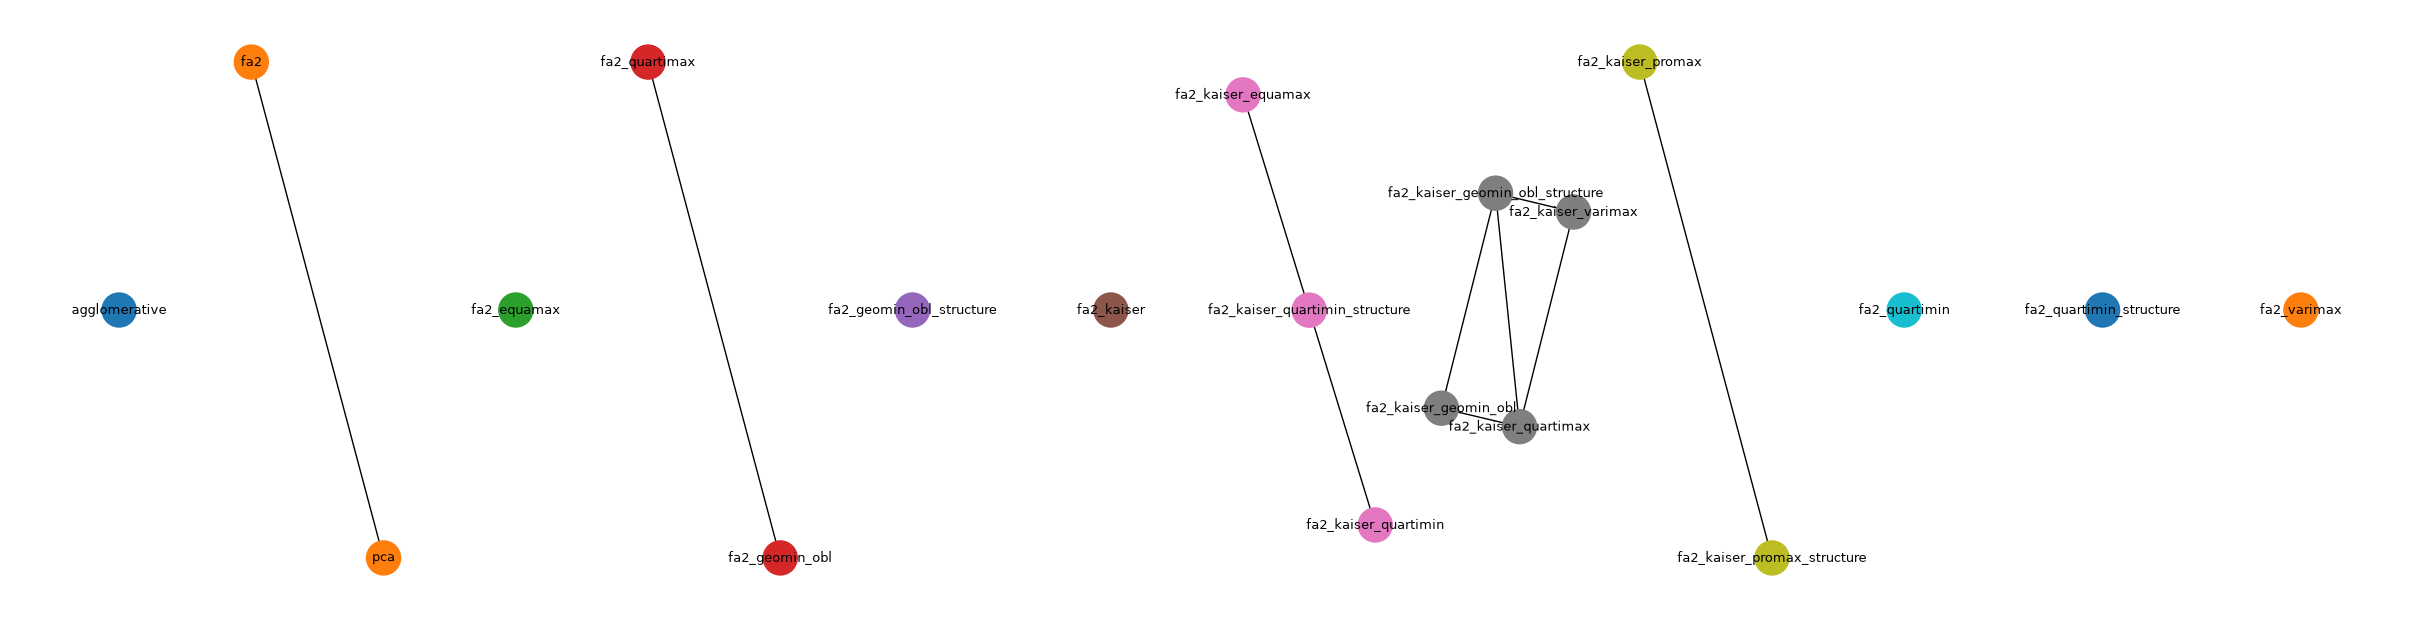

In [97]:
# chosen_nodes = ["pca", "agglomerative", "fa2_kaiser_varimax", "fa2_kaiser_geomin_obl", "fa2_kaiser_geomin_obl_structure"]
# adj = tests[1].unstack().loc[chosen_nodes, chosen_nodes] > 0.05
adj = tests[1].unstack() > 0.05
G = nx.from_pandas_adjacency(adj)

components = list(nx.connected_components(G))
colors = itertools.cycle(plt.cm.tab10.colors)
color_map = {}
pos = {}
x_offset = 0
for comp, color in zip(components, colors):
    subG = G.subgraph(comp)
    sub_pos = nx.spring_layout(subG, k=1.2, seed=42)
    for node, (x, y) in sub_pos.items():
        pos[node] = (x + x_offset, y)
        color_map[node] = color
    x_offset += 3  # space between components
node_color=[color_map[n] for n in G.nodes()]

plt.figure(figsize=(24, 6))
nx.draw(G, pos, with_labels=True, node_color=node_color, node_size=600, font_size=9)
plt.show()

### AR scores

In [ ]:
save_to(make_AR_scores(best_indexes), "AR_scores/mac/hac_best_k_indexes.pickle")

In [65]:
save_to(make_AR_scores(best_indexes), "AR_scores/mac/hac_best_k_indexes.pickle")

[00:00:08] Processed collecttion 1
[00:00:11] Processed collecttion 2
[00:00:19] Processed collecttion 3
[00:00:22] Processed collecttion 4
[00:00:30] Processed collecttion 5
[00:00:39] Processed collecttion 6
[00:00:59] Processed collecttion 7
[00:01:07] Processed collecttion 8


In [105]:
save_to(make_AR_scores(silhouette), "AR_scores/mac/hac_silhouette.pickle")

[00:00:08] Processed collecttion 1
[00:00:17] Processed collecttion 2
[00:00:26] Processed collecttion 3
[00:00:35] Processed collecttion 4
[00:00:54] Processed collecttion 5
[00:01:13] Processed collecttion 6
[00:01:33] Processed collecttion 7
[00:01:52] Processed collecttion 8


In [106]:
save_to(make_AR_scores(dunn.rdiff), "AR_scores/mac/hac_dunn_rdiff.pickle")

[00:00:02] Processed collecttion 1
[00:00:05] Processed collecttion 2
[00:00:08] Processed collecttion 3
[00:00:11] Processed collecttion 4
[00:00:19] Processed collecttion 5
[00:00:28] Processed collecttion 6
[00:00:36] Processed collecttion 7
[00:00:45] Processed collecttion 8


In [107]:
save_to(make_AR_scores(ptbiserial), "AR_scores/mac/hac_ptbiserial.pickle")

[00:00:02] Processed collecttion 1
[00:00:05] Processed collecttion 2
[00:00:07] Processed collecttion 3
[00:00:10] Processed collecttion 4
[00:00:19] Processed collecttion 5
[00:00:28] Processed collecttion 6
[00:00:36] Processed collecttion 7
[00:00:45] Processed collecttion 8


In [108]:
save_to(make_AR_scores(davies_bouldin.ldiff), "AR_scores/mac/hac_davies_bouldin_ldiff.pickle")

[00:00:02] Processed collecttion 1
[00:00:05] Processed collecttion 2
[00:00:08] Processed collecttion 3
[00:00:11] Processed collecttion 4
[00:00:19] Processed collecttion 5
[00:00:27] Processed collecttion 6
[00:00:35] Processed collecttion 7
[00:00:43] Processed collecttion 8


In [136]:
elapsed = make_stopwatch()
results = {}
n_collections = len(collections)
for i, colle in enumerate(collections):
    for name, [X, labels_true] in colle.items():
        labels_true, k_true = fix_labels(labels_true)
        corr = X.corr().abs()
        try:
            tree = AgglomerativeTree().fit(corr)
            labels_pred, _ = fix_labels(tree.predict(k_true))
            results[name] = adjusted_rand_score(labels_true, labels_pred)
        except Exception as ex:
            print(f"[{elapsed()}] {name} error: {ex}")
    print(f"[{elapsed()}] Processed collecttion {i+1}")
    
save_to(results, "AR_scores/mac/hac_omniscient.pickle")

[00:00:00] Processed collecttion 1
[00:00:01] Processed collecttion 2
[00:00:01] Processed collecttion 3
[00:00:02] Processed collecttion 4
[00:00:03] Processed collecttion 5
[00:00:04] Processed collecttion 6
[00:00:06] Processed collecttion 7
[00:00:07] Processed collecttion 8


In [48]:
save_to(make_AR_scores_latent(fa2_predict), "AR_scores/mac/fa2.pickle")

[00:00:05] Processed collecttion 1
[00:00:13] Processed collecttion 2
[00:00:16] Processed collecttion 3
[00:00:21] Processed collecttion 4
[00:00:35] Processed collecttion 5
[00:00:50] Processed collecttion 6
[00:00:59] Processed collecttion 7
[00:01:08] Processed collecttion 8


In [ ]:
collections_scores_latent(fa2_kaiser_predict)

In [56]:
save_to(make_AR_scores_latent(fa2_kaiser_predict), "AR_scores/mac/fa2_kaiser.pickle")

[00:00:11] Processed collecttion 1
[00:00:36] Processed collecttion 2
[00:00:49] Processed collecttion 3
[00:01:19] Processed collecttion 4
[00:02:25] Processed collecttion 5
[00:04:29] Processed collecttion 6
[00:05:56] Processed collecttion 7
[00:08:02] Processed collecttion 8


In [ ]:
# collections_scores_latent(fa_predict)

In [ ]:
collections_scores_latent(partial(fa2_rot2_predict, rotation="varimax"))

In [57]:
save_to(make_AR_scores_latent(partial(fa2_rot2_predict, rotation="varimax")), "AR_scores/mac/fa2_varimax.pickle")

[00:00:09] Processed collecttion 1
[00:00:20] Processed collecttion 2
[00:00:26] Processed collecttion 3
[00:00:33] Processed collecttion 4
[00:00:59] Processed collecttion 5
[00:01:27] Processed collecttion 6
[00:01:46] Processed collecttion 7
[00:02:05] Processed collecttion 8


In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="varimax"))

In [58]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="varimax")), "AR_scores/mac/fa2_kaiser_varimax.pickle")

[00:00:11] Processed collecttion 1
[00:00:38] Processed collecttion 2
[00:00:50] Processed collecttion 3
[00:01:21] Processed collecttion 4
[00:02:29] Processed collecttion 5
[00:04:31] Processed collecttion 6
[00:05:59] Processed collecttion 7
[00:08:04] Processed collecttion 8


In [ ]:
# collections_scores_latent(partial(fa_rot2_predict, rotation="varimax"))

In [ ]:
# collections_scores_latent(favm_predict)

In [ ]:
collections_scores_latent(partial(fa2_rot2_predict, rotation="quartimax"))

In [59]:
save_to(make_AR_scores_latent(partial(fa2_rot2_predict, rotation="quartimax")), "AR_scores/mac/fa2_quartimax.pickle")

[00:01:11] Processed collecttion 1
[00:02:36] Processed collecttion 2
[00:03:39] Processed collecttion 3
[00:04:55] Processed collecttion 4
[00:09:22] Processed collecttion 5
[00:14:21] Processed collecttion 6
[00:18:52] Processed collecttion 7
[00:23:45] Processed collecttion 8


In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="quartimax"))

In [60]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="quartimax")), "AR_scores/mac/fa2_kaiser_quartimax.pickle")

[00:00:12] Processed collecttion 1
[00:00:42] Processed collecttion 2
[00:00:55] Processed collecttion 3
[00:01:30] Processed collecttion 4
[00:02:45] Processed collecttion 5
[00:05:02] Processed collecttion 6
[00:06:37] Processed collecttion 7
[00:08:57] Processed collecttion 8


In [ ]:
# collections_scores_latent(partial(fa_rot2_predict, rotation="quartimax"))

In [ ]:
# collections_scores_latent(faqm_predict)

In [62]:
save_to(make_AR_scores_latent(partial(fa2_rot2_predict, rotation="geomin_obl")), "AR_scores/mac/fa2_geomin_obl.pickle")

[00:00:34] Processed collecttion 1
[00:01:14] Processed collecttion 2
[00:01:46] Processed collecttion 3
[00:02:22] Processed collecttion 4
[00:03:46] Processed collecttion 5
[00:05:16] Processed collecttion 6
[00:06:40] Processed collecttion 7
[00:08:02] Processed collecttion 8


In [63]:
save_to(make_AR_scores_latent(partial(fa2_rot2_structure_predict, rotation="geomin_obl")), "AR_scores/mac/fa2_geomin_obl_structure.pickle")

[00:00:34] Processed collecttion 1
[00:01:13] Processed collecttion 2
[00:01:45] Processed collecttion 3
[00:02:21] Processed collecttion 4
[00:03:45] Processed collecttion 5
[00:05:15] Processed collecttion 6
[00:06:39] Processed collecttion 7
[00:08:01] Processed collecttion 8


In [64]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="geomin_obl")), "AR_scores/mac/fa2_kaiser_geomin_obl.pickle")

[00:00:13] Processed collecttion 1
[00:00:44] Processed collecttion 2
[00:00:59] Processed collecttion 3
[00:01:35] Processed collecttion 4
[00:02:50] Processed collecttion 5
[00:05:09] Processed collecttion 6
[00:06:44] Processed collecttion 7
[00:09:04] Processed collecttion 8


In [65]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_structure_predict, rotation="geomin_obl")), "AR_scores/mac/fa2_kaiser_geomin_obl_structure.pickle")

[00:00:13] Processed collecttion 1
[00:00:44] Processed collecttion 2
[00:00:58] Processed collecttion 3
[00:01:33] Processed collecttion 4
[00:02:48] Processed collecttion 5
[00:05:06] Processed collecttion 6
[00:06:42] Processed collecttion 7
[00:09:01] Processed collecttion 8


In [137]:
paths = [
    "AR_scores/mac/fa2.pickle",
    "AR_scores/mac/fa2_kaiser.pickle",
    "AR_scores/mac/fa2_varimax.pickle",
    "AR_scores/mac/fa2_kaiser_varimax.pickle",
    "AR_scores/mac/fa2_quartimax.pickle",
    "AR_scores/mac/fa2_kaiser_quartimax.pickle",
    "AR_scores/mac/fa2_equamax.pickle",
    "AR_scores/mac/fa2_kaiser_equamax.pickle",
    "AR_scores/mac/fa2_quartimin.pickle",
    "AR_scores/mac/fa2_quartimin_structure.pickle",
    "AR_scores/mac/fa2_kaiser_quartimin.pickle",
    "AR_scores/mac/fa2_kaiser_quartimin_structure.pickle",
    "AR_scores/mac/fa2_geomin_obl.pickle",
    "AR_scores/mac/fa2_geomin_obl_structure.pickle",
    "AR_scores/mac/fa2_kaiser_geomin_obl.pickle",
    "AR_scores/mac/fa2_kaiser_geomin_obl_structure.pickle",
    "AR_scores/mac/fa2_kaiser_promax.pickle",
    "AR_scores/mac/fa2_kaiser_promax_structure.pickle",
    "AR_scores/mac/pca.pickle",
    "AR_scores/mac/pca_kaiser.pickle",
    "AR_scores/mac/pca_jolliffe_kaiser.pickle",
    "AR_scores/mac/pca_mle.pickle",
    "AR_scores/mac/hac_omniscient.pickle",
    "AR_scores/mac/hac_best_k_indexes.pickle",
    "AR_scores/mac/hac_silhouette.pickle",
    "AR_scores/mac/hac_ptbiserial.pickle",
    "AR_scores/mac/hac_dunn_rdiff.pickle",
    "AR_scores/mac/hac_davies_bouldin_ldiff.pickle",
]
rows = {}
for p in paths:
    p = Path(p)
    means = {
        co_i: scores.mean()
        for co_i, scores in per_collection(load_from(p)).items()
    }
    rows[p.stem] = means

pd.DataFrame(rows).T

,1,2,3,4,5,6,7,8
fa2,0.559363,0.562313,0.714817,0.720798,0.794583,0.798291,0.863300,0.856912
fa2_kaiser,0.528029,0.464040,0.704111,0.630272,0.784949,0.744689,0.869070,0.814966
fa2_varimax,0.766427,0.766619,0.649718,0.648846,0.594188,0.607537,0.691856,0.700888
fa2_kaiser_varimax,0.994030,0.868090,0.997136,0.864938,0.982044,0.949217,0.994893,0.955179
fa2_quartimax,0.828258,0.806274,0.681512,0.671300,0.706531,0.703948,0.735995,0.727818
fa2_kaiser_quartimax,0.993933,0.862455,0.996875,0.857847,0.987184,0.943149,0.995222,0.949050
fa2_equamax,0.142060,0.100875,0.140567,0.115164,0.054305,0.052713,0.064110,0.068181
fa2_kaiser_equamax,0.989552,0.840778,0.994019,0.837516,0.854577,0.695137,0.877346,0.721136
fa2_quartimin,0.371287,0.351320,0.349806,0.343895,0.095313,0.098927,0.113627,0.125665
fa2_quartimin_structure,0.453065,0.440302,0.393590,0.383669,0.197556,0.200867,0.196008,0.209032


In [126]:
pd.DataFrame({
        co_i: scores.mean()
        for co_i, scores in per_collection(load_from("AR_scores/mac/ignore/fa_geomin_obl.pickle")).items()
    }, index=["fe_geomin"])

,1,2,3,4,5,6,7,8
fe_geomin,0.997476,0.973368,0.994613,0.97013,0.994934,0.994413,0.996435,0.992114


In [67]:
results = []
for colle, index in zip(collections, best_index_per_collection):
    results.append(external_scores(colle, index, adjusted_rand_score).describe())
pd.concat(results, keys=range(1, 9), axis=1)

,1,2,3,4,5,6,7,8
count,1000.0,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1.0,0.989512,0.999444,0.978467,0.997284,0.992251,0.968783,0.932084
std,0.0,0.057023,0.017568,0.096094,0.034900,0.058754,0.103926,0.170118
min,1.0,0.161813,0.444444,0.065606,0.488649,0.396183,0.305656,0.005822
25%,1.0,1.000000,1.000000,0.990666,1.000000,1.000000,1.000000,0.969388
50%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [110]:
collections_scores(best_indexes)

[00:00:08] Processed collecttion 1
[00:00:11] Processed collecttion 2
[00:00:19] Processed collecttion 3
[00:00:22] Processed collecttion 4
[00:00:30] Processed collecttion 5
[00:00:39] Processed collecttion 6
[00:00:59] Processed collecttion 7
[00:01:07] Processed collecttion 8


,1,2,3,4,5,6,7,8
count,1000.0,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1.0,0.989512,0.999444,0.978467,0.997284,0.992251,0.968783,0.932084
std,0.0,0.057023,0.017568,0.096094,0.034900,0.058754,0.103926,0.170118
min,1.0,0.161813,0.444444,0.065606,0.488649,0.396183,0.305656,0.005822
25%,1.0,1.000000,1.000000,0.990666,1.000000,1.000000,1.000000,0.969388
50%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [112]:
collections_scores_latent(pca_predict)

[00:00:00] Processed collecttion 1
[00:00:01] Processed collecttion 2
[00:00:02] Processed collecttion 3
[00:00:02] Processed collecttion 4
[00:00:04] Processed collecttion 5
[00:00:06] Processed collecttion 6
[00:00:07] Processed collecttion 7
[00:00:09] Processed collecttion 8


,1,2,3,4,5,6,7,8
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.550131,0.563272,0.681000,0.698790,0.792465,0.801526,0.861108,0.855632
std,0.201236,0.187833,0.199679,0.189957,0.204269,0.198433,0.170648,0.164794
min,-0.011494,-0.090909,-0.190476,-0.120000,0.199374,0.168140,0.099744,0.355882
25%,0.426018,0.447090,0.550198,0.568627,0.638752,0.640217,0.738870,0.724406
50%,0.549461,0.569098,0.659836,0.694801,0.864411,0.888713,0.940005,0.932959
75%,0.670845,0.682406,0.836614,0.830674,1.000000,0.989299,1.000000,0.997043
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
collections_scores_latent(partial(fa2_rot2_predict, rotation="quartimin"))

In [61]:
save_to(make_AR_scores_latent(partial(fa2_rot2_predict, rotation="quartimin")), "AR_scores/mac/fa2_quartimin.pickle")

[00:00:33] Processed collecttion 1
[00:01:12] Processed collecttion 2
[00:01:43] Processed collecttion 3
[00:02:18] Processed collecttion 4
[00:03:43] Processed collecttion 5
[00:05:15] Processed collecttion 6
[00:06:40] Processed collecttion 7
[00:08:03] Processed collecttion 8


In [ ]:
# collections_scores_latent(partial(fa2_rot2_structure_predict, rotation="quartimin"))

In [49]:
save_to(make_AR_scores_latent(partial(fa2_rot2_structure_predict, rotation="quartimin")), "AR_scores/mac/fa2_quartimin_structure.pickle")

[00:00:33] Processed collecttion 1
[00:01:12] Processed collecttion 2
[00:01:43] Processed collecttion 3
[00:02:18] Processed collecttion 4
[00:03:42] Processed collecttion 5
[00:05:14] Processed collecttion 6
[00:06:38] Processed collecttion 7
[00:08:01] Processed collecttion 8


In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="quartimin"))

In [62]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="quartimin")), "AR_scores/mac/fa2_kaiser_quartimin.pickle")

[00:00:12] Processed collecttion 1
[00:00:43] Processed collecttion 2
[00:00:57] Processed collecttion 3
[00:01:34] Processed collecttion 4
[00:02:48] Processed collecttion 5
[00:05:05] Processed collecttion 6
[00:06:41] Processed collecttion 7
[00:09:00] Processed collecttion 8


In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_structure_predict, rotation="quartimin"))

In [63]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_structure_predict, rotation="quartimin")), "AR_scores/mac/fa2_kaiser_quartimin_structure.pickle")

[00:00:12] Processed collecttion 1
[00:00:43] Processed collecttion 2
[00:00:57] Processed collecttion 3
[00:01:34] Processed collecttion 4
[00:02:48] Processed collecttion 5
[00:05:05] Processed collecttion 6
[00:06:41] Processed collecttion 7
[00:09:00] Processed collecttion 8


In [ ]:
# collections_scores_latent(partial(fa_rot2_predict, rotation="quartimin"))

In [ ]:
# collections_scores_latent(partial(fa_rot2_structure_predict, rotation="quartimin"))

In [65]:
save_to(make_AR_scores_latent(fa2_equamax_predict), "AR_scores/mac/fa2_equamax.pickle")

[00:00:47] Processed collecttion 1
[00:01:46] Processed collecttion 2
[00:02:37] Processed collecttion 3
[00:03:38] Processed collecttion 4
[00:07:48] Processed collecttion 5
[00:12:26] Processed collecttion 6
[00:17:09] Processed collecttion 7
[00:22:15] Processed collecttion 8


In [ ]:
collections_scores_latent(fa2_kaiser_equamax_predict)

In [67]:
save_to(make_AR_scores_latent(fa2_kaiser_equamax_predict), "AR_scores/mac/fa2_kaiser_equamax.pickle")

[00:00:12] Processed collecttion 1
[00:00:44] Processed collecttion 2
[00:00:58] Processed collecttion 3
[00:01:34] Processed collecttion 4
[00:02:50] Processed collecttion 5
[00:05:06] Processed collecttion 6
[00:06:44] Processed collecttion 7
[00:09:07] Processed collecttion 8


In [ ]:
# collections_scores_latent(partial(fa_rot2_predict, rotation="equamax", kappa=0.5))

In [68]:
save_to(make_AR_scores_latent(partial(fa2_rot2_predict, rotation="promax")), "AR_scores/mac/fa2_promax.pickle")

[00:00:00] F[(3)2] R[(3)40] v0 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v1 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v2 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v3 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v4 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v5 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v6 error: Singular matrix
[00:00:00] F[(3)2] R[(3)40] v7 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v0 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v1 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v2 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v3 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v4 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v5 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v6 error: Singular matrix
[00:00:00] F[(3)2] R[(3)50] v7 error: Singular matrix
[00:00:00] F[(3)2] R[(3)60] v0 error: Singular matrix
[00:00:00] F[(3)2] R[(3)60] v1 error: Singular matrix
[00:00:00] F[(3)2] R[(3)60] 

/Users/myk/mamba/envs/sci/lib/python3.14/site-packages/factor_analyzer/rotator.py:578: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.757509951631232e-24.
  diag_inv = np.diag(sp.linalg.inv(np.dot(coef.T, coef)))


[00:00:21] F[(5)3] R[(4)70,35] v6 error: Singular matrix
[00:00:21] F[(5)3] R[(4)70,35] v7 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v0 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v1 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v2 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v3 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v4 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v5 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v6 error: Singular matrix
[00:00:21] F[(5)3] R[70,62,55,48,40] v7 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v0 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v1 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v2 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v3 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v4 error: Singular matrix
[00:00:21] F[(5)3] R[42,52,54,81,83] v5 error: Singular matrix
[00:

In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="promax"))

In [69]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_predict, rotation="promax")), "AR_scores/mac/fa2_kaiser_promax.pickle")

[00:00:11] Processed collecttion 1
[00:00:38] Processed collecttion 2
[00:00:51] Processed collecttion 3
[00:01:21] Processed collecttion 4
[00:02:29] Processed collecttion 5
[00:04:34] Processed collecttion 6
[00:06:03] Processed collecttion 7
[00:08:09] Processed collecttion 8


In [ ]:
collections_scores_latent(partial(fa2_kaiser_rot2_structure_predict, rotation="promax"))

In [70]:
save_to(make_AR_scores_latent(partial(fa2_kaiser_rot2_structure_predict, rotation="promax")), "AR_scores/mac/fa2_kaiser_promax_structure.pickle")

[00:00:11] Processed collecttion 1
[00:00:38] Processed collecttion 2
[00:00:51] Processed collecttion 3
[00:01:21] Processed collecttion 4
[00:02:29] Processed collecttion 5
[00:04:34] Processed collecttion 6
[00:06:03] Processed collecttion 7
[00:08:09] Processed collecttion 8


In [37]:
save_to(make_AR_scores_latent(partial(fa_rot2_predict, rotation="geomin_obl")), "AR_scores/mac/fa_geomin_obl.pickle")

[00:00:24] Processed collecttion 1
[00:00:55] Processed collecttion 2
[00:01:21] Processed collecttion 3
[00:01:54] Processed collecttion 4
[00:03:10] Processed collecttion 5
[00:04:32] Processed collecttion 6
[00:05:53] Processed collecttion 7
[00:07:13] Processed collecttion 8


In [50]:
save_to(make_AR_scores_latent(pca_predict), "AR_scores/mac/pca.pickle")

[00:00:00] Processed collecttion 1
[00:00:01] Processed collecttion 2
[00:00:02] Processed collecttion 3
[00:00:03] Processed collecttion 4
[00:00:04] Processed collecttion 5
[00:00:06] Processed collecttion 6
[00:00:07] Processed collecttion 7
[00:00:09] Processed collecttion 8


In [118]:
save_to(make_AR_scores_latent(pca_mle_predict), "AR_scores/mac/pca_mle.pickle")

[00:00:01] Processed collecttion 1
[00:00:04] Processed collecttion 2
[00:00:06] Processed collecttion 3
[00:00:08] Processed collecttion 4
[00:00:17] Processed collecttion 5
[00:00:28] Processed collecttion 6
[00:00:37] Processed collecttion 7
[00:00:47] Processed collecttion 8


In [121]:
save_to(make_AR_scores_latent(pca_kaiser_predict), "AR_scores/mac/pca_kaiser.pickle")

[00:00:00] Processed collecttion 1
[00:00:01] Processed collecttion 2
[00:00:02] Processed collecttion 3
[00:00:03] Processed collecttion 4
[00:00:04] Processed collecttion 5
[00:00:06] Processed collecttion 6
[00:00:07] Processed collecttion 7
[00:00:09] Processed collecttion 8


In [122]:
save_to(make_AR_scores_latent(pca_jolliffe_kaiser_predict), "AR_scores/mac/pca_jolliffe_kaiser.pickle")

[00:00:01] Processed collecttion 1
[00:00:02] Processed collecttion 2
[00:00:03] Processed collecttion 3
[00:00:04] Processed collecttion 4
[00:00:07] Processed collecttion 5
[00:00:10] Processed collecttion 6
[00:00:12] Processed collecttion 7
[00:00:15] Processed collecttion 8
